In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Ejercicio 1 — Binarización de una imagen

1. Usa la función de OpenCV  threshold para hacer binarización simple de una imagen en escala de grises. Habrá que usar el argumento apropiado para ello.

2. Averigua qué otros tipos de binarizaciones se pueden hacer.

Consulta el tutorial: https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html 

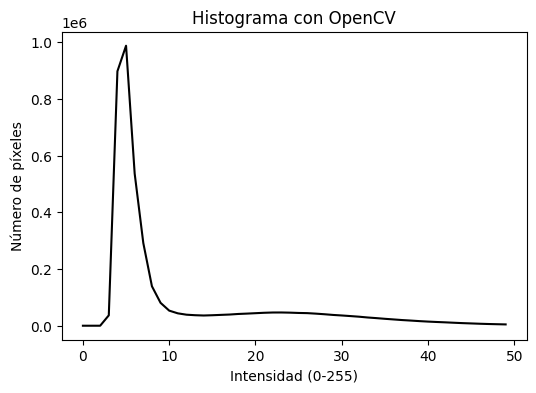

In [63]:
# Cargar imagen
img_gris = cv.imread("img1_rgba.tif", 0)

hist_cv = cv.calcHist([img_gris], [0], None, [50], [0,50])

# Dibujar histograma
plt.figure(figsize=(6,4))
plt.plot(hist_cv, color='black')
plt.title("Histograma con OpenCV")
plt.xlabel("Intensidad (0-255)")
plt.ylabel("Número de píxeles")
plt.show()


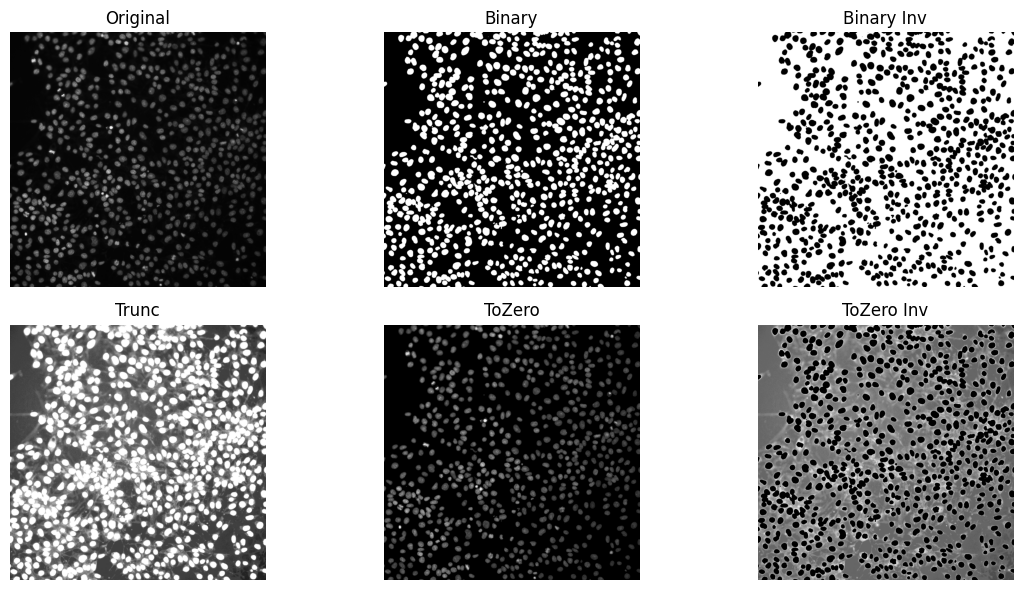

In [67]:

thresh_val = 10 #umbral T que divide los píxeles
max_val = 255 #valor asignado cuando un píxel supera el umbral

# --- 1. Binarización simple (THRESH_BINARY) ---
_, bin_simple = cv.threshold(img_gris, thresh_val, max_val, cv.THRESH_BINARY)

# --- 2. Otros tipos de binarización ---
_, bin_inv = cv.threshold(img_gris, thresh_val, max_val, cv.THRESH_BINARY_INV)
_, trunc = cv.threshold(img_gris, thresh_val, max_val, cv.THRESH_TRUNC)
_, tozero = cv.threshold(img_gris, thresh_val, max_val, cv.THRESH_TOZERO)
_, tozero_inv = cv.threshold(img_gris, thresh_val, max_val, cv.THRESH_TOZERO_INV)

# --- 3. Mostrar resultados ---
titles = ["Original", "Binary", "Binary Inv", "Trunc", "ToZero", "ToZero Inv"]
images = [img_gris, bin_simple, bin_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(12,6))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [68]:
np.amax(trunc)

np.uint8(10)

## Ejercicio 2 — Método de Otsu

1. Averigua qué argumento hay que añadir a la función threshold para calcular la umbralización de Otsu. Compáralo con una binarización simple.

Consulta el tutorial: https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html 

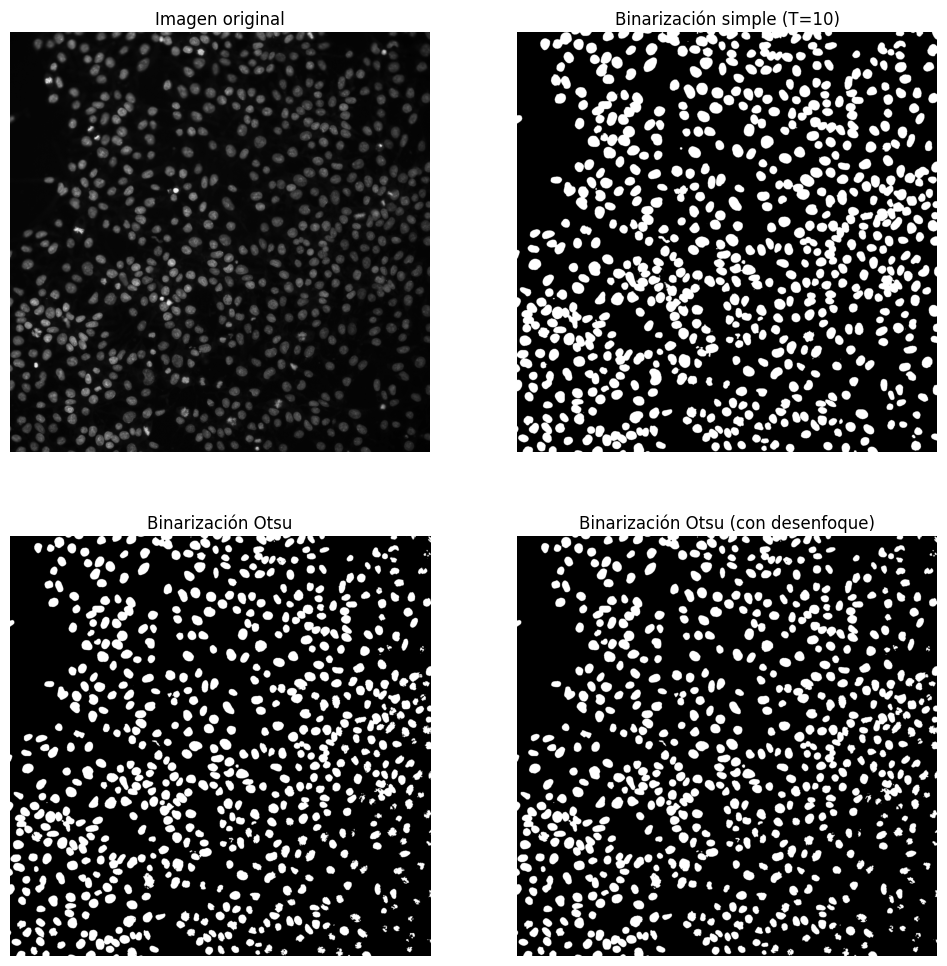

In [69]:
# 2) Umbralización de Otsu
# Aquí el argumento extra es cv.THRESH_OTSU
# Nota: el segundo argumento (umbral) se ignora, OpenCV lo calcula automáticamente
_, bin_otsu = cv.threshold(img_gris, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Otsu's thresholding after Gaussian filtering
blur = cv.GaussianBlur(img_gris,(5,5),0)
_,bin_otsu2 = cv.threshold(blur,0,255,cv.THRESH_OTSU)

# Visualizamos
plt.figure(figsize=(12,12))

plt.subplot(2,2,1)
plt.imshow(img_gris, cmap='gray')
plt.title("Imagen original")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(bin_simple, cmap='gray')
plt.title("Binarización simple (T=10)")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(bin_otsu, cmap='gray')
plt.title("Binarización Otsu")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(bin_otsu2, cmap='gray')
plt.title("Binarización Otsu (con desenfoque)")
plt.axis("off")

plt.show()

## Ejercicio 3 — Umbralización local o adaptativa

1. Averigua qué opciones ofrece OpenCV  para hacer umbralización adaptativa. ¿Qué tipos de condiciones locales implementa en cada caso? 

2. Busca imágenes en las que funcione mejor una umbralización adaptativa.

Consulta el tutorial: https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html 


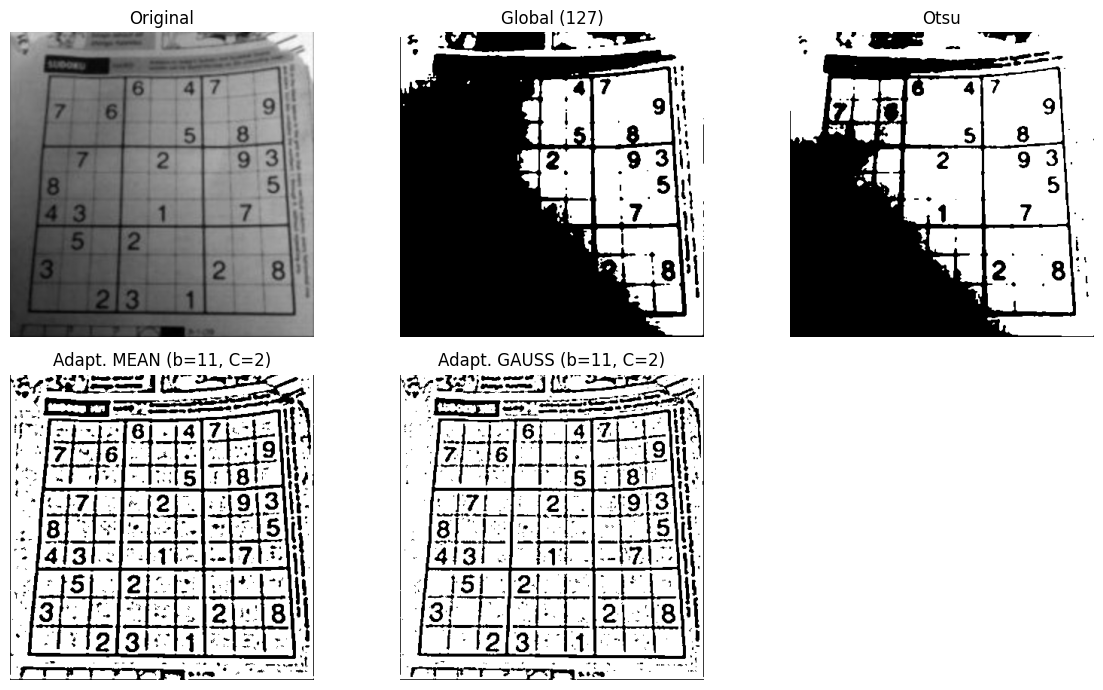

In [ ]:
img_sudoku = cv.imread("sudoku.png", 0)

# (Opcional) Suavizado ligero para reducir ruido
img_blur = cv.medianBlur(img_sudoku, 3)

# Global (referencia)
_, th_global = cv.threshold(img_blur, 127, 255, cv.THRESH_BINARY)

# Otsu (referencia global automática)
_, th_otsu = cv.threshold(img_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# Adaptativa MEAN
blockSize = 11   # impar y acorde a la escala del fondo/ruido blockSize: Pequeño (11–21) para variaciones locales rápidas; Grande (31–61) para gradientes amplios de iluminación.
C = 2            # ajustar según contraste local. C: si ves “fugas” de fondo a blanco, sube C; si pierdes detalles, baja C.

th_mean = cv.adaptiveThreshold(img_blur, 255,
                               cv.ADAPTIVE_THRESH_MEAN_C,
                               cv.THRESH_BINARY,
                               blockSize, C)

# Adaptativa GAUSSIAN
th_gauss = cv.adaptiveThreshold(img_blur, 255,
                                cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv.THRESH_BINARY,
                                blockSize, C)

# Visualización
titulos = ["Original", "Global (127)", f"Otsu", 
          f"Adapt. MEAN (b={blockSize}, C={C})", 
          f"Adapt. GAUSS (b={blockSize}, C={C})"]
imgs = [img_sudoku, th_global, th_otsu, th_mean, th_gauss]

plt.figure(figsize=(12,7))
for i,(im,t) in enumerate(zip(imgs,titulos),1):
    plt.subplot(2,3,i); plt.imshow(im, cmap="gray"); plt.title(t); plt.axis("off")
plt.tight_layout(); plt.show()

## Ejercicio 4 — Agrupamiento

1. Usa la función de OpenCV  kmeans para hacer una segmentación de pastes de una imagen sencilla como la del ejemplo. En realidad estamos haciendo una cuantización del color. 

2. Investiga cómo son los argumentos de entrada y cómo es la salida.

Consulta el tutorial: https://docs.opencv.org/4.x/d1/d5c/tutorial_py_kmeans_opencv.html 


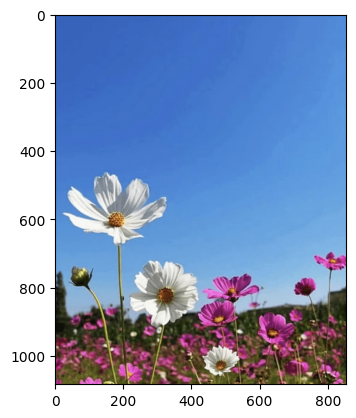

In [38]:
img = cv.imread("flores.png", cv.IMREAD_COLOR)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

plt.imshow(img_rgb)


`compactness, labels, centers = cv.kmeans(data, K, bestLabels, criteria, attempts, flags)`

### Entradas:

`data` → matriz de datos float32 de tamaño (N, d).

Para color: d=3 (BGR/RGB).

Para grises: d=1 (intensidad).

`K` → número de clusters.

`bestLabels` → generalmente None (OpenCV la rellena).

`criteria` → criterio de parada: tupla (type, max_iter, epsilon):

`type`: cv.TERM_CRITERIA_EPS, cv.TERM_CRITERIA_MAX_ITER o ambos.

`max_iter`: nº máximo de iteraciones (p.ej. 20).

`epsilon`: cambio mínimo para parar (p.ej. 1.0).

`attempts` → cuántas veces reintenta con inicializaciones distintas (devuelve la mejor).

`flags` → inicialización de centros:

    cv.KMEANS_PP_CENTERS (recomendado),

    cv.KMEANS_RANDOM_CENTERS.

### Salidas:

`compactness` → suma de distancias cuadradas dentro del cluster (menor es mejor).

`labels` → vector (N,1) con la etiqueta de cluster asignada a cada fila de data.

`centers` → matriz (K,d) con los centroides finales (en el mismo espacio que data).

(925736, 3)


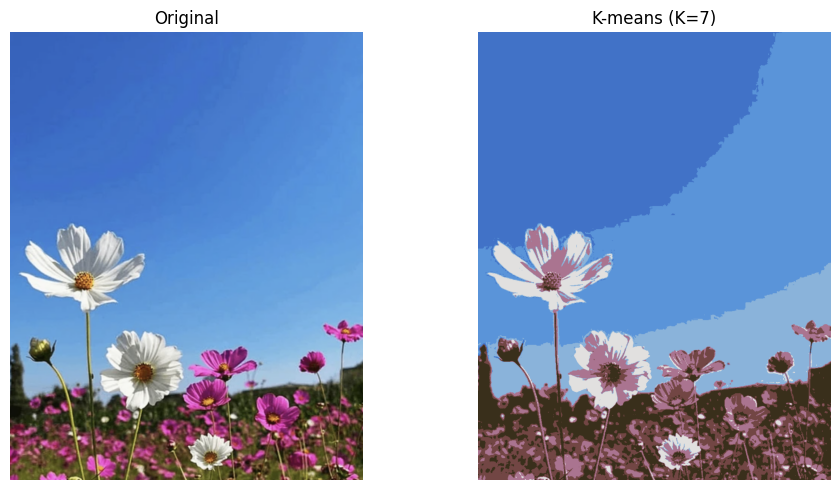

In [43]:

# 2) Preparar datos para k-means: (N,3) y float32
Z = img.reshape((-1, 3))           # N x 3
Z = np.float32(Z)                  # OpenCV kmeans necesita float32
print(Z.shape)  # Verificar dimensiones

# 3) Parámetros de k-means
K = 7  # número de grupos (clusters)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 20, 1.0)
attempts = 5
flags = cv.KMEANS_PP_CENTERS       # inicialización tipo k-means++

# 4) Ejecutar kmeans
compactness, labels, centers = cv.kmeans(Z, K, None, criteria, attempts, flags)

# 5) Reconstrucción de imagen cuantizada
centers = np.uint8(centers)        # vuelve a 8 bits para imagen
seg = centers[labels.flatten()]    # reemplaza cada píxel por su centro
seg_img = seg.reshape(img.shape)   # (H, W, 3) en BGR
seg_rgb = cv.cvtColor(seg_img, cv.COLOR_BGR2RGB)

# 6) Visualización
plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.imshow(img_rgb); plt.title(f"Original"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(seg_rgb); plt.title(f"K-means (K={K})"); plt.axis("off")
plt.tight_layout(); plt.show()



# Watershed

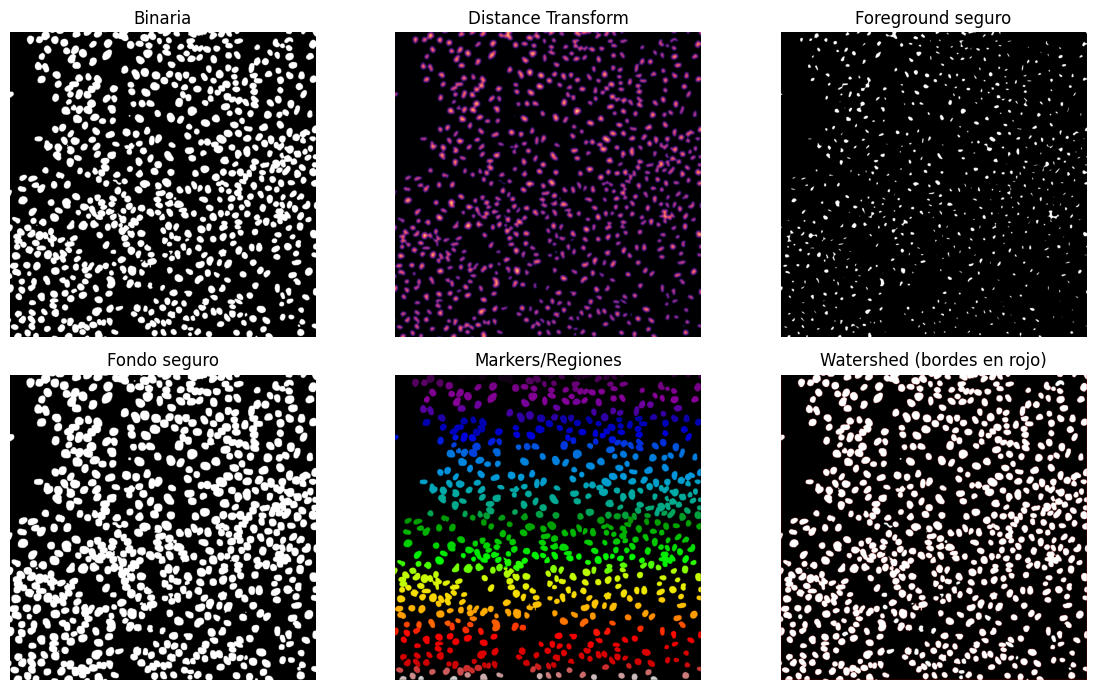

In [ ]:
# 1) Asegurar tipo y limpiar un poco
bin_clean = cv.medianBlur(bin_simple, 3)

# 2) Fondo seguro (sure background) por dilatación
kernel = np.ones((3,3), np.uint8)
sure_bg = cv.dilate(bin_clean, kernel, iterations=3)

# 3) Foreground seguro con distance transform
#    (la DT asume píxeles no-cero como foreground)
dist = cv.distanceTransform(bin_clean, distanceType=cv.DIST_L2, maskSize=5)
# Umbral relativo al máximo para obtener “picos” bien dentro de los objetos
_, sure_fg = cv.threshold(dist, 0.5 * dist.max(), 255, cv.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

# 4) Zona desconocida (bordes entre objetos/fondo)
unknown = cv.subtract(sure_bg, sure_fg)

# 5) Etiquetado de componentes conectados sobre el foreground seguro
#    markers: 0=desconocido, 1=fondo, 2..N=objetos
num_labels, markers = cv.connectedComponents(sure_fg)
markers = markers + 1            # 1 será el fondo
markers[unknown==255] = 0        # 0 será la zona desconocida

# 6) Watershed necesita una imagen 3 canales (usamos la binaria como BGR para demo)
img_color = cv.cvtColor(bin_simple, cv.COLOR_GRAY2BGR)

# 7) Ejecutar watershed
markers_ws = cv.watershed(img_color, markers.copy())  # int32 interno; bordes = -1

# 8) Visualización de resultados
#    - Bordes de watershed en rojo
vis = img_color.copy()
vis[markers_ws == -1] = [0, 0, 255]

plt.figure(figsize=(12,7))
plt.subplot(2,3,1); plt.imshow(bin_clean, cmap='gray'); plt.title('Binaria'); plt.axis('off')
plt.subplot(2,3,2); plt.imshow(dist, cmap='magma'); plt.title('Distance Transform'); plt.axis('off')
plt.subplot(2,3,3); plt.imshow(sure_fg, cmap='gray'); plt.title('Foreground seguro'); plt.axis('off')
plt.subplot(2,3,4); plt.imshow(sure_bg, cmap='gray'); plt.title('Fondo seguro'); plt.axis('off')
plt.subplot(2,3,5); plt.imshow(markers_ws, cmap='nipy_spectral'); plt.title('Markers/Regiones'); plt.axis('off')
plt.subplot(2,3,6); plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB)); plt.title('Watershed (bordes en rojo)'); plt.axis('off')
plt.tight_layout(); plt.show()

Text(0.5, 1.0, 'Watershed (bordes en rojo)')

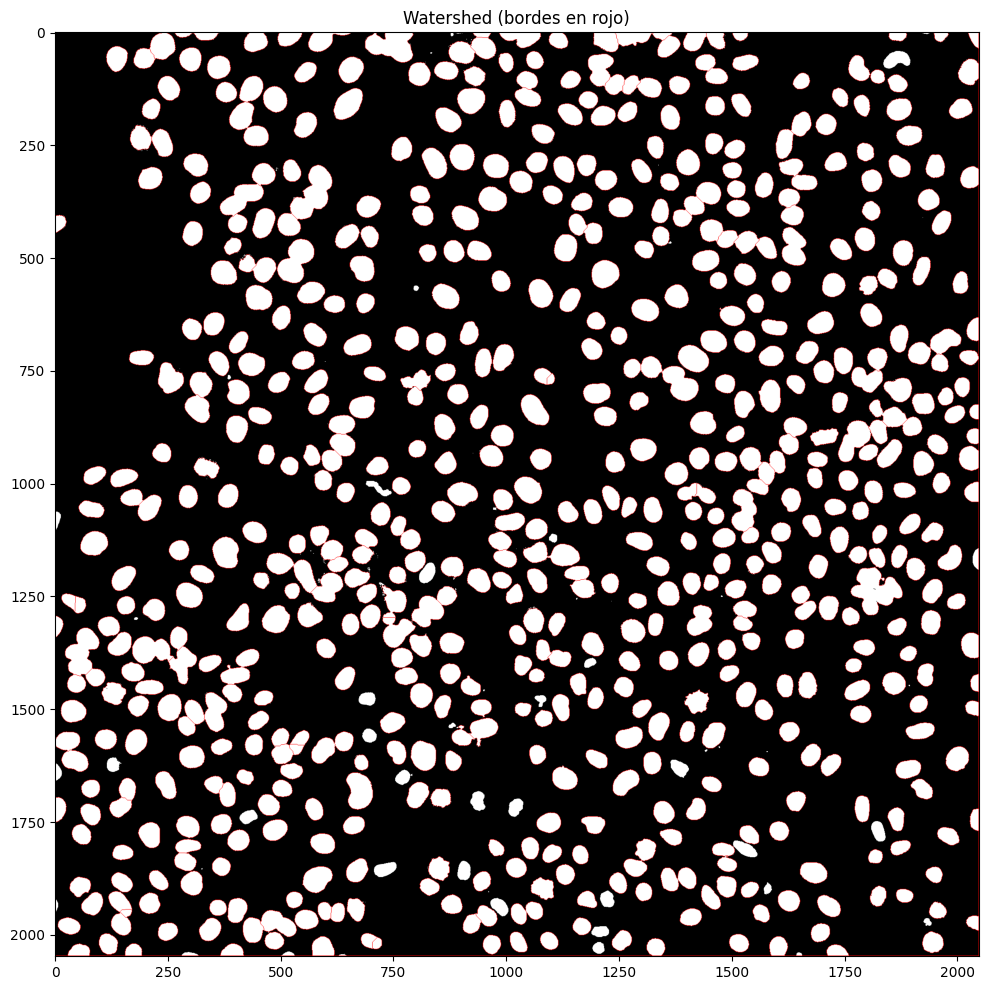

In [50]:
plt.figure(figsize=(12,12))
plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB)); plt.title('Watershed (bordes en rojo)')